# Example notebook

In [ ]:
#________ IMPORT ________#

#__ Topophone2 __
from topophone2.modelling import ArrayCovarianceModel
from topophone2.inversion import Uniform, Posterior, LinearFlowsModel, VI

#__ Numerical __
import numpy as np
import scipy.stats as stats
import harmonic as hm

#__ Plotting __
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmcrameri.cm as cmc
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Print statement __
print("Imported modules.")

In [16]:
#________ READ SIMULATION ________#

#__ Import HDF5 reader __
import h5py

#__ Open file __
with h5py.File('../testing/abyssal_T-phase_sim.h5', 'r') as hf:

    #__ Wavefield __
    slowness_T = hf['sim_output/slowness_T'][:]   # (sensor, source, mode, direction) [s.m-1]
    energy_T   = hf['sim_output/energy_T'][:]     # (sensor, source, mode)            [uPa2.Hz-1]
    slowness_J = hf['sim_output/slowness_J'][:]   # (source, direction)               [s.m-1]
    energy_J   = hf['sim_output/energy_J'][:]     # (source)                          [uPa2.Hz-1]

    #__ Truth __
    m_true_T = hf['sim_output/m_true_T'][:]       # (sensor, parameter)
    a_true   = hf['sim_output/a'][:]              # (order)
    b_true   = hf['sim_output/b'][:]              # (order)

    #__ Geometry __
    xR = hf['geom/xR'][:]                         # (sensor, direction) [m]
    az = hf['geom/azS_J'][:]                      # (source)            [rad]
    f  = hf['geom'].attrs['f']                    # [Hz]
    s0 = hf['geom'].attrs['s0']                   # [s.m-1]

#__ Print statement __
print("Loaded simulation.")

Loaded simulation.


In [17]:
#________ SET UP INVERSIONS ________#

#__ Sensor geometries __
x_triad = xR[1:]  # Sensor position (triad) [m] (sensor, direction)
x_quad  = xR      # Sensor position (full)  [m] (sensor, direction)

#__ Frequency vector __
bw    = 1/3                                   # Frequency vector bandwidth [8ve]
nf    = 5                                     # Number of frequency bins
f_vec = f * 2.0**(np.linspace(-1,1,nf)*bw/2)  # Frequency vector [Hz] (frequency)
freq  = 2 * np.pi * f_vec                     # Frequency vector [rad.s-1] (frequency)

#__ Example data __
r_triad = x_triad[None,:,:] - x_triad[:,None,:]  # Sensor separation (triad) [m] (sensor, sensor, direction)
r_quad  = x_quad[None,:,:]  - x_quad[:,None,:]   # Sensor separation (full)  [m] (sensor, sensor, direction)
Gamma_T_triad = np.einsum(                       # Signal array covariance (triad) (frequency, sensor, sensor)
    'pq,fpqjk->fjk',
    np.nan_to_num(energy_T[0], nan=0.0),
    np.exp(1j * np.einsum('f,jkl,pql->fpqjk', freq, r_triad, np.nan_to_num(slowness_T[0], nan=0.0)))
)
Gamma_T_quad  = np.einsum(                       # Signal array covariance (full) (frequency, sensor, sensor)
    'pq,fpqjk->fjk',
    np.nan_to_num(energy_T[0], nan=0.0),
    np.exp(1j * np.einsum('f,jkl,pql->fpqjk', freq, r_quad, np.nan_to_num(slowness_T[0], nan=0.0)))
)
Gamma_J_triad = np.einsum(                       # Noise array covariance (triad) (frequency, sensor, sensor)
    'p,fpjk->fjk',
    energy_J,
    np.exp(1j * np.einsum('f,jkl,pl->fpjk', freq, r_triad, slowness_J))
)
Gamma_J_quad  = np.einsum(                       # Noise array covariance (full) (frequency, sensor, sensor)
    'p,fpjk->fjk',
    energy_J,
    np.exp(1j * np.einsum('f,jkl,pl->fpjk', freq, r_quad, slowness_J))
)
Gamma_TJ_triad = Gamma_T_triad + Gamma_J_triad  # Array covariance (full) (frequency, sensor, sensor)
Gamma_TJ_quad  = Gamma_T_quad  + Gamma_J_quad   # Array covariance (full) (frequency, sensor, sensor)

#__ Inversion parameters __
sigs = ['normal', {'sig':'noise2D', 's':s0, 'max_order':1}]
lower  = np.array([50.,  -5.0e-4, 8.0e-5, 1.0e-6, 1.0e-6, -0.99, 50., -0.8, -0.8])
upper  = np.array([100., -4.2e-4, 1.6e-4, 5.0e-5, 5.0e-5,  0.99, 100., 0.8,  0.8])
N_flow = 8
learning_rate = 5e-4
iterations    = 30000
nsample       = 100
nout          = int(iterations/5000)
N_samples     = 5000

#__ Number of observations __
Nobs_T = 16
Nobs_J = 32

#__ Truth vector for signal __
m_true = np.append(m_true_T[0], np.array([75., a_true[1], b_true[1]]))

#__ Print statement __
print("Set up inversion.")

Set up inversion.


In [18]:
#________ INVERSION HELPER ________#

#__ Helper __
def decompose(
    Gamma         : np.ndarray=None,
    Gamma_n       : np.ndarray = None,
    Nobs          : int=None,
    Nobs_n        : int        = None,
    x             : np.ndarray=None,
    freq          : np.ndarray=None,
    sigs          : list=None,
    weight_units  : str        = 'dB',
    custom_cf     : dict       = {},
    prior_bounds  : tuple=None,
    N_flow        : int=None,
    mean_field    : bool       = False,
    ini_dist      : str        = 'Uniform',
    learning_rate : float=None,
    outpath       : str        = '.',
    iterations    : int=None,
    nsample       : int=None,
    nout          : int        = 1,
    save_intermediate_result : bool = False,
    verbose       : bool       = False,
    N_samples     : int=None,
    model_outpath : str        = None,
    loss_outpath  : str        = None,
    unpack        : bool       = False,
    return_loss   : bool       = False
) -> np.ndarray:
    r'''
    `Gamma` : `numpy.ndarray`
        Observed array-covariance matrix
        (frequency, sensor, sensor)

    `Gamma_n` : `numpy.ndarray`
        Observed noise-only array-covariance matrix
        (frequency, sensor, sensor)

    `Nobs` : `int`
        Degrees of freedom

    `Nobs_n` : `int`
        Degrees of freedom (noise)

    `x` : `numpy.ndarray`
        Sensor position [m]
        (sensor, direction)

    `freq` : `numpy.ndarray`
        Angular frequency vector [rad.s-1]
        (frequency)

    `sigs` : `list`
        List of signals

    `weight_units` : `str`
        Units of the signal weights in the model vector
        ('dB' or 'linear')

    `custom_cf` : `dict`
        Custom characteristic functions keyed by signal name

    `prior_bounds` : `(numpy.ndarray,numpy.ndarray)`
        Prior bounds

    `N_flow` : `int`
        Number of normalising flows

    `mean_field` : `bool`
        Use mean-field approximation

    `ini_dist` : `str`
        Initial distribution to transform

    `learning_rate` : `float`

    `outpath` : `str`


    '''

    #__ Set up array-covariance model __
    if (Gamma_n is not None) : calc_noise_only = True
    else:                      calc_noise_only = False
    model = ArrayCovarianceModel(
        x               = x,
        freq            = freq,
        signal_types    = sigs,
        weight_units    = weight_units,
        calc_noise_only = calc_noise_only,
        custom_cf       = custom_cf
    )

    #__ Set up prior pdf __
    prior = Uniform(*prior_bounds)

    #__ Set up posterior pdf __
    posterior = Posterior(
        Gamma_obs             = Gamma,
        N_obs                 = Nobs,
        arraycovariance_model = model,
        prior                 = prior,
        Gamma_obs_noise       = Gamma_n,
        N_obs_noise           = Nobs_n
    )

    #__ Set up normalising flow model __
    flow = LinearFlowsModel(
        N_param      = len(prior_bounds[0]),
        prior_bounds = prior_bounds,
        N_flow       = N_flow,
        mean_field   = mean_field,
        ini_dist     = ini_dist
    )

    #__ Set up inverse problem __
    inverse = VI(
        flow_model    = flow,
        posterior     = posterior,
        learning_rate = learning_rate,
        outpath       = outpath
    )

    #__ Perform inversion __
    inverse.invert(
        iterations = iterations,
        nsample    = nsample,
        nout       = nout,
        save_intermediate_result = save_intermediate_result,
        verbose    = verbose
    )
    loss = inverse.loss_his

    #__ Sample posterior __
    m = inverse.sample(N_samples=N_samples)

    #__ Save models __
    if model_outpath: np.savetxt(model_outpath, m)
    if loss_outpath : np.savetxt(loss_outpath,  loss)

    #__ Unpack __
    if unpack: m = inverse.unpack(m)

    #__ Return output __
    if return_loss: return m, loss
    else:           return m, posterior

#__ Print statement __
print("Defined inversion helper function.")

Defined inversion helper function.


In [19]:
#__ Triad inversion __
m_triad, post_triad = decompose(
    Gamma   = Gamma_TJ_triad,
    Nobs    = Nobs_T,
    Gamma_n = Gamma_J_triad,
    Nobs_n  = Nobs_J,
    x       = x_triad,
    freq    = freq,
    sigs    = sigs,
    prior_bounds  = (lower,upper),
    N_flow        = N_flow,
    learning_rate = learning_rate,
    iterations    = iterations,
    nsample       = nsample,
    nout          = nout,
    verbose = True,
    N_samples     = N_samples
)

----------------------------------------

Iteration:     0,	Loss:   47972.93
The elapsed time is: 0.21 s
Iteration:  5000,	Loss:   13919.05
The elapsed time is: 64.29 s
Iteration: 10000,	Loss:   13851.10
The elapsed time is: 128.17 s
Iteration: 15000,	Loss:   13849.36
The elapsed time is: 191.35 s
Iteration: 20000,	Loss:   13849.47
The elapsed time is: 251.97 s
Iteration: 25000,	Loss:   13849.41
The elapsed time is: 311.99 s
Iteration: 30000,	Loss:   13849.40
The elapsed time is: 371.99 s
----------------------------------------

Finish training!


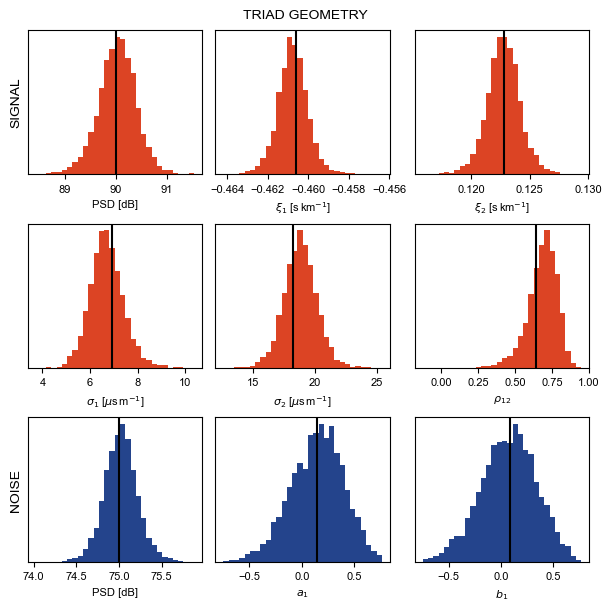

In [20]:
#________ PLOT HISTOGRAMS ________#

#__ Create figure and axes __
fig, axs = plt.subplots(
    nrows=3, ncols=3,
    figsize=(6,6), facecolor='white', layout='constrained'
)

#__ Set labels and scales __
labels = [
    r"PSD [dB]", r"$\xi_1$ [s$\,$km$^{-1}$]", r"$\xi_2$ [s$\,$km$^{-1}$]",
    r"$\sigma_1$ [$\mu$s$\,$m$^{-1}$]", r"$\sigma_2$ [$\mu$s$\,$m$^{-1}$]", r"$\rho_{12}$",
    r"PSD [dB]", r"$a_1$", r"$b_1$"
]
scales = [
    1e0, 1e3, 1e3,
    1e6, 1e6, 1e0,
    1e0, 1e0, 1e0
]

#__ Format __
fig.suptitle('TRIAD GEOMETRY', fontsize=large)
axs[0,0].set_ylabel('SIGNAL', fontsize=large)
axs[2,0].set_ylabel('NOISE',  fontsize=large)
for ax, lab in zip(axs.flatten(), labels):
    ax.set_xlabel(lab, fontsize=small)
    ax.set_yticks([])
    ax.tick_params(labelsize=small)

#__ Plot histograms __
for i, (ax, sc) in enumerate(zip(axs.flatten(), scales)):
    if (i < 6): c = theme[0]
    else:       c = theme[2]
    ax.hist(sc*m_triad[:,i], bins=30, color=c, zorder=1)
    ax.axvline(sc*m_true[i], color='k', zorder=2)

#__ Show figure __
fig.show()

In [21]:
#________ COMPUTE EVIDENCE ________#

#__ Helper function __
def calc_evidence(m, lnL, lnV, nchains=10, temperature=0.8):
    
    #__ Reshape __
    ndim = m.shape[-1]
    m = m.reshape(nchains, -1, ndim)
    lnprob = (lnL - lnV).reshape(nchains, -1)

    chains = hm.Chains(ndim)
    chains.add_chains_3d(m, lnprob)
    chains_train, chains_infer = hm.utils.split_data(chains, training_proportion=0.5)

    model = hm.model.RQSplineModel(ndim, standardize=True, temperature=temperature)
    model.fit(chains_train.samples)

    ev = hm.Evidence(chains_infer.nchains, model)
    ev.add_chains(chains_infer)

    ln_Z, _ = ev.compute_ln_evidence()
    err_lo, err_hi = ev.compute_ln_inv_evidence_errors()
    return ln_Z, (err_lo, err_hi)

# #__ Calculate likelihood __
lnL_triad, _ = post_triad.log_likelihood(m_triad, grad=False)

# #__ Calculate prior volume __
lnV_triad = np.sum(np.log(upper-lower))

#__ Calculate the evidence __
ln_Z_triad, err_triad = calc_evidence(m_triad, lnL_triad, lnV_triad)


In [22]:
ln_Z_triad

np.float32(-13850.525)